# AI Research Radar: Mapping the AI Research Landscape with Sentence Embeddings

**Author:** Anas Khan · Data Science student

Thousands of AI papers appear on arXiv every month, so nobody can read them all. This project uses **sentence embeddings**, the same technology behind semantic search and retrieval-augmented generation (RAG), to answer:

1. What are the main research topics in AI right now?
2. Which topics are **rising** and which are **fading** (January 2024 to September 2026)?
3. How often do key ideas such as *agents*, *reasoning* and *RAG* appear over time?
4. Does **semantic search** find relevant papers that keyword search misses?

**Method in one line:** arXiv API → title + abstract → `all-MiniLM-L6-v2` embeddings (384 dimensions, CPU) → k-means topics → class-based TF-IDF keywords → monthly topic shares and trend slopes → t-SNE map → semantic search app.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from radar import nlp, dashboard as D

ROOT = Path("..").resolve()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

papers = pd.read_parquet(ROOT / "data" / "processed" / "papers_with_topics.parquet")
vectors = np.load(ROOT / "data" / "processed" / "embeddings.npy")
topics = pd.read_csv(ROOT / "data" / "processed" / "topics.csv")
print(f"{len(papers):,} papers · {papers['month'].min()} to {papers['month'].max()} · embeddings {vectors.shape}")

12,060 papers · 2024-01 to 2026-09 · embeddings (12060, 384)


## 1. The corpus

In [2]:
per_month = papers.groupby("month").size()
print(f"Papers per month: min {per_month.min()}, median {int(per_month.median())}, max {per_month.max()}")
print("Primary categories (top 8):")
print((papers["primary_category"].value_counts(normalize=True).head(8) * 100).round(1).to_string())

Papers per month: min 300, median 360, max 420
Primary categories (top 8):
primary_category
cs.LG      30.1
cs.CL      20.1
cs.AI      11.2
cs.CV      11.1
cs.CR       2.9
stat.ML     2.4
cs.RO       2.3
cs.SE       1.9


The sample has **12,060 papers**, 300–420 per month. That steady count comes from the sampling design (60 papers per 5-day window), not from arXiv's real volume, which is far larger and growing. So this analysis measures **what share of AI research goes to each topic**, not how many papers exist. Most papers have cs.LG (30%) or cs.CL (20%) as their primary category; the rest are papers cross-listed into the three sampled categories from computer vision, security, robotics and others.

## 2. How many topics? Silhouette scores

In [3]:
k_scores = nlp.choose_k(vectors, candidates=(15, 20, 25, 30, 35))
k_scores.round(4)

,k,silhouette
0,15,0.0555
1,20,0.0553
2,25,0.0554
3,30,0.0563
4,35,0.0591


Silhouette scores are low (about 0.055–0.059) and almost flat across k = 15 to 35. That is normal for text: research topics overlap and blend into each other instead of forming separate islands, so no k is clearly "correct". I used **k = 25** because it was the most granular setting where every topic still read as one coherent research area when I checked its keywords and a sample of titles. Larger k mostly split big areas, such as LLM training, into fragments that were hard to tell apart.

## 3. The topics

In [4]:
pd.set_option("display.max_colwidth", 90)
topics.assign(share_pct=(topics["papers"] / topics["papers"].sum() * 100).round(1))[["name", "papers", "share_pct", "keywords"]]

,name,papers,share_pct,keywords
0,"LLM training, alignment & fine-tuning",767,6.4,"training, attention, fine-tuning, tokens, context, memory, knowledge, translation"
1,Multimodal & vision-language models,698,5.8,"visual, multimodal, image, video, vision-language, mllms, reasoning, images"
2,Multilingual NLP & text analysis,672,5.6,"text, human, sentiment, social, evaluation, analysis, english, dataset"
3,LLM reasoning & math,619,5.1,"reasoning, knowledge, mathematical, capabilities, questions, accuracy, cot, answer"
4,Reinforcement learning,607,5.0,"reinforcement, policy, rl, reward, optimization, policies, algorithm, agents"
5,"Retrieval, RAG & search",568,4.7,"retrieval, knowledge, rag, generation, information, semantic, retrieval-augmented, query"
6,LLM agents & code generation,563,4.7,"agents, agent, generation, execution, software, evaluation, tool, benchmark"
7,General ML: fairness & generalization,544,4.5,"machine, training, causal, samples, datasets, domain, classification, distribution"
8,Adversarial attacks & AI security,536,4.4,"attacks, attack, adversarial, security, safety, detection, backdoor, defense"
9,Computer vision: detection & segmentation,523,4.3,"images, image, object, detection, segmentation, vision, dataset, feature"


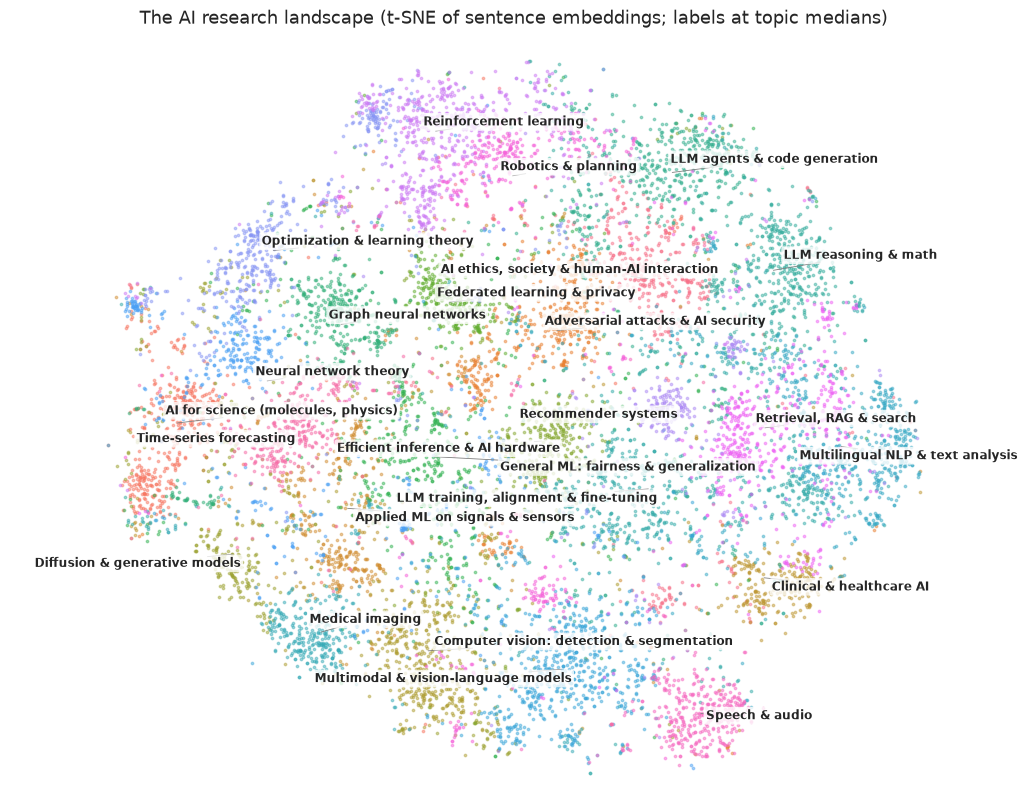

In [5]:
fig, ax = plt.subplots(figsize=(13, 10))
palette = sns.color_palette("husl", papers["topic"].nunique())
from adjustText import adjust_text
labels = []
for i, (topic, g) in enumerate(papers.groupby("topic_name")):
    ax.scatter(g["x"], g["y"], s=3, alpha=.45, color=palette[i])
    labels.append(ax.text(g["x"].median(), g["y"].median(), topic, fontsize=8.5, weight="bold", ha="center",
                          bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=.8)))
ax.margins(x=0.12, y=0.04)
adjust_text(labels, ax=ax, expand=(1.15, 1.4), arrowprops=dict(arrowstyle="-", color="grey", lw=.6))
ax.set_axis_off()
ax.set_title("The AI research landscape (t-SNE of sentence embeddings; labels at topic medians)", fontsize=13)
save(fig, "01_topic_map")
plt.show()

The 25 topics cover the field well, from **LLM training and alignment** (6.4% of papers), **multimodal models** and **reasoning** to **AI for science**, **medical imaging** and **recommender systems**. Topic names were written by hand after reading each topic's class-based TF-IDF keywords and sample titles. On the map, related areas sit next to each other: medical imaging is close to clinical AI, and agents are close to reasoning and code. Some topics are broader than their names suggest; "Applied ML on signals & sensors", for instance, mixes EEG, battery and other sensor-prediction work.

## 4. Rising and falling topics

In [6]:
shares = nlp.topic_shares(papers, "topic_name")
trends = nlp.trend_table(shares)
trends.round(2)

,share_first_6m_pct,share_last_6m_pct,change_pp,slope_pp_per_year,growth_ratio
LLM agents & code generation,2.11,9.81,7.70,3.27,4.64
LLM reasoning & math,3.21,6.11,2.90,1.67,1.90
Efficient inference & AI hardware,2.24,5.60,3.36,1.46,2.50
Optimization & learning theory,3.55,5.65,2.10,0.82,1.59
"AI ethics, society & human-AI interaction",2.99,4.91,1.92,0.79,1.64
Robotics & planning,2.53,3.89,1.35,0.73,1.53
Adversarial attacks & AI security,3.64,5.23,1.59,0.62,1.44
Diffusion & generative models,2.42,2.92,0.49,0.34,1.20
Reinforcement learning,5.56,5.28,-0.29,0.13,0.95
Multimodal & vision-language models,4.93,5.00,0.07,0.07,1.01


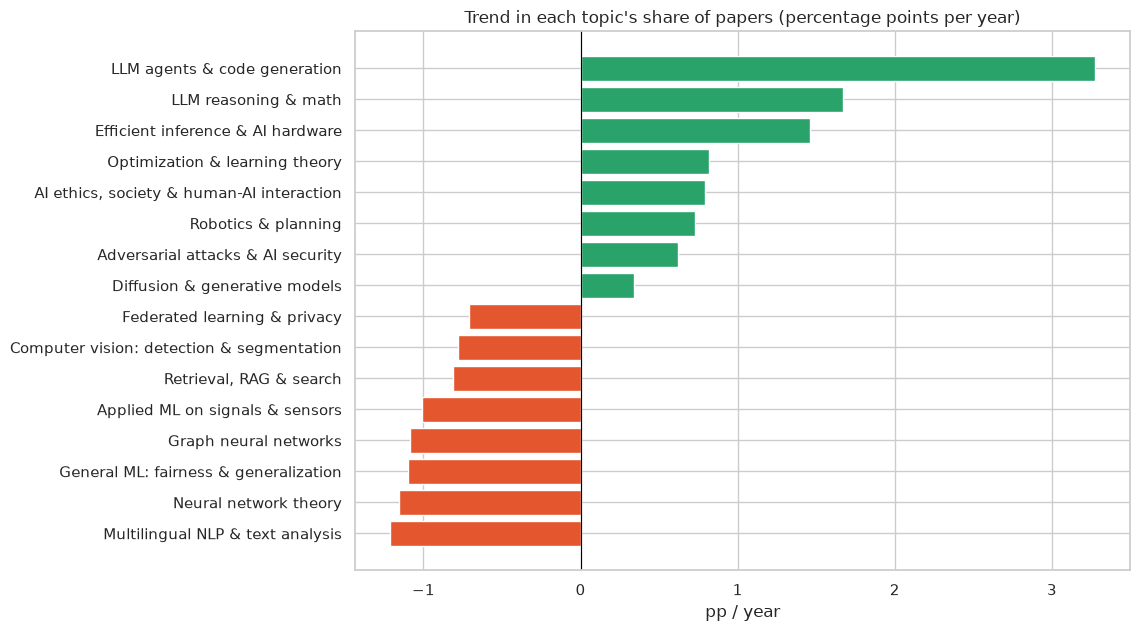

In [7]:
top = pd.concat([trends.head(8), trends.tail(8)])
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.index[::-1], top["slope_pp_per_year"][::-1],
        color=["#29A36A" if v > 0 else "#E4572E" for v in top["slope_pp_per_year"][::-1]])
ax.axvline(0, color="black", lw=.8)
ax.set(title="Trend in each topic's share of papers (percentage points per year)", xlabel="pp / year")
save(fig, "02_rising_falling")
plt.show()

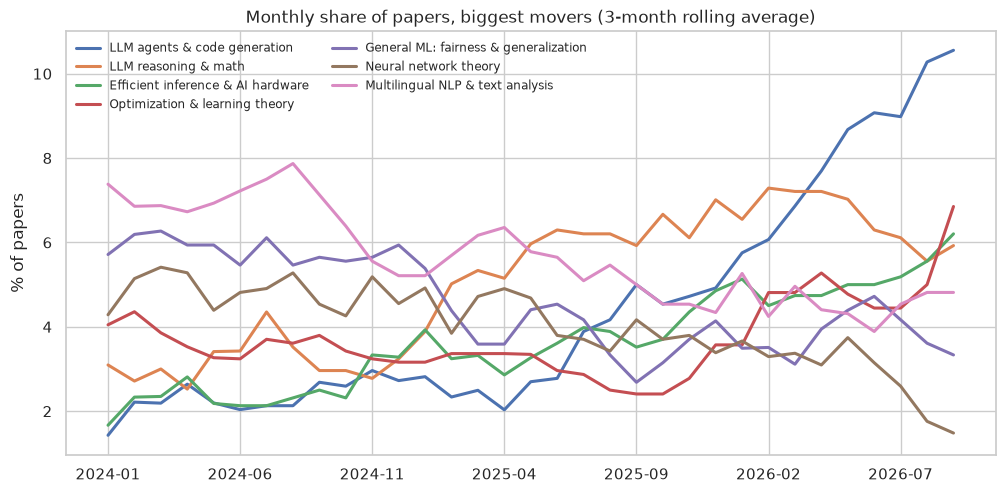

In [8]:
movers = list(trends.index[:4]) + list(trends.index[-3:])
fig, ax = plt.subplots(figsize=(12, 5.5))
(shares[movers] * 100).rolling(3, min_periods=1).mean().plot(ax=ax, lw=2.2)
ax.set(title="Monthly share of papers, biggest movers (3-month rolling average)", xlabel="", ylabel="% of papers")
ax.legend(fontsize=8.5, frameon=False, ncol=2)
save(fig, "03_movers")
plt.show()

- **LLM agents & code generation is the clear breakout topic.** Its share of papers rose from **2.1% in the first six months to 9.8% in the last six (4.6×)**. Growth was slow through mid-2025 and then accelerated sharply.
- **Reasoning** (3.2% → 6.1%) and **efficient inference & AI hardware** (2.2% → 5.6%, covering quantization, KV caches and serving) are the next fastest risers. This is consistent with the field's 2025–26 focus on reasoning models and the cost of running them.
- Falling shares: **graph neural networks** (4.3% → 1.8%), **federated learning** (3.0% → 1.1%), **neural network theory** (5.1% → 2.3%) and **multilingual/classic NLP** (7.1% → 4.4%). Falling share does not mean these areas are dying, only that they are growing more slowly than the rest of AI.
- The **retrieval/RAG topic's share fell** (5.8% → 4.1%) even though papers *mentioning* RAG doubled (see the next section). One plausible explanation is that retrieval is increasingly a component inside agent systems rather than a research topic of its own. That is an interpretation, not something this data proves.

## 5. Key ideas over time

In [9]:
kw = nlp.keyword_trends(papers)
summary = pd.DataFrame({"first_6m_pct": kw.head(6).mean(), "last_6m_pct": kw.tail(6).mean()})
summary["change_pp"] = summary["last_6m_pct"] - summary["first_6m_pct"]
summary["ratio"] = summary["last_6m_pct"] / summary["first_6m_pct"]
summary.sort_values("change_pp", ascending=False).round(2)

,first_6m_pct,last_6m_pct,change_pp,ratio
AI agents,6.59,22.87,16.28,3.47
Reasoning,5.68,16.90,11.22,2.98
Multimodal / vision-language,6.25,10.51,4.26,1.68
Retrieval-augmented generation,1.69,3.38,1.69,2.00
Mixture of experts,0.60,2.22,1.62,3.70
Test-time compute,0.81,2.36,1.55,2.91
LoRA / fine-tuning efficiency,1.35,2.69,1.33,1.98
Reinforcement learning,7.01,8.24,1.23,1.17
Diffusion models,4.06,5.28,1.22,1.30
Chain-of-thought,1.48,2.18,0.69,1.47


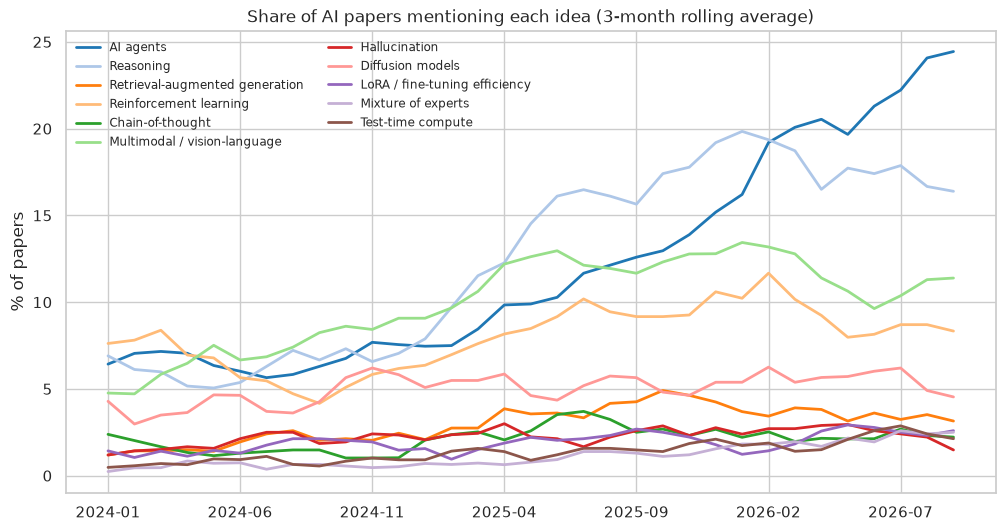

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
kw.rolling(3, min_periods=1).mean().plot(ax=ax, lw=2, color=sns.color_palette("tab20", kw.shape[1]))
ax.set(title="Share of AI papers mentioning each idea (3-month rolling average)", xlabel="", ylabel="% of papers")
ax.legend(fontsize=8.5, frameon=False, ncol=2)
save(fig, "04_keywords")
plt.show()

- Papers mentioning **agents** rose from **6.6% to 22.9%** of the sample (3.5×). By the end of the period, roughly one AI paper in five mentions agents.
- **Reasoning** mentions tripled (5.7% → 16.9%); **mixture of experts** (0.6% → 2.2%, 3.7×) and **test-time compute** (0.8% → 2.4%, 2.9×) grew fastest from small bases.
- **Hallucination** stayed nearly flat (1.8% → 2.0%), and **chain-of-thought** grew only modestly. Ideas that became standard practice tend to be mentioned less explicitly over time.
- Keyword matching is a blunt instrument (for example, "agent" also matches reinforcement-learning agents), so these numbers show direction and scale, not exact counts.

## 6. Semantic search vs. keyword search

Keyword search only finds papers that contain the exact words typed. Semantic search compares **meanings**: the query is embedded with the same model, and papers are ranked by cosine similarity.

In [11]:
model = nlp.load_model()
queries = ["making language models admit when they don't know something",
           "robots learning tasks by watching videos",
           "cheaper ways to fine-tune big models on a single GPU"]
for q in queries:
    sem = nlp.semantic_search(q, vectors, papers, model=model, top_k=5)
    kws = nlp.keyword_search(q, papers, top_k=5)
    print(f"\nQUERY: {q}")
    print(f"  keyword search: {len(nlp.keyword_search(q, papers, top_k=10**6))} papers contain every word")
    for _, r in sem.iterrows():
        print(f"  [{r['similarity']:.2f}] {r['title'][:110]}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4062.30it/s]


QUERY: making language models admit when they don't know something


  keyword search: 0 papers contain every word
  [0.57] Do LLMs Know about Hallucination? An Empirical Investigation of LLM's Hidden States
  [0.55] Emergent Introspective Awareness in Large Language Models
  [0.53] Explaining Black-box Language Models with Knowledge Probing Systems: A Post-hoc Explanation Perspective
  [0.53] Do Large Language Models Know What They Are Capable Of?
  [0.52] LLMs' Understanding of Natural Language Revealed



QUERY: robots learning tasks by watching videos


  keyword search: 0 papers contain every word
  [0.55] Visual IRL for Human-Like Robotic Manipulation
  [0.54] Interactive Continual Learning Architecture for Long-Term Personalization of Home Service Robots
  [0.53] Video2Policy: Scaling up Manipulation Tasks in Simulation through Internet Videos
  [0.53] Who Can We Trust? Scope-Aware Video Moment Retrieval with Multi-Agent Conflict
  [0.52] Accelerated Multi-objective Task Learning using Modified Q-learning Algorithm



QUERY: cheaper ways to fine-tune big models on a single GPU


  keyword search: 0 papers contain every word
  [0.57] QoS-Efficient Serving of Multiple Mixture-of-Expert LLMs Using Partial Runtime Reconfiguration
  [0.56] Patterns behind Chaos: Forecasting Data Movement for Efficient Large-Scale MoE LLM Inference
  [0.55] Debunking the CUDA Myth Towards GPU-based AI Systems
  [0.54] KVPR: Efficient LLM Inference with I/O-Aware KV Cache Partial Recomputation
  [0.53] Learning Scalable Model Soup on a Single GPU: An Efficient Subspace Training Strategy


For all three everyday-language queries, **keyword search found zero papers**, because no abstract contains every word of "making language models admit when they don't know something". Semantic search returned clearly relevant results for the first query (papers on LLM self-knowledge and hallucination) and partly relevant results for the others: *Video2Policy* and *Visual IRL* match "robots learning by watching videos", but some neighbours are only loosely related. For the fine-tuning query, most matches were about cheap **inference** rather than **fine-tuning**, which shows the limit of a small 22M-parameter embedding model. A larger embedding model, hybrid keyword + semantic ranking, or a cross-encoder re-ranker would be the next improvements; this is the same retrieval step a RAG system depends on.

## 7. Interactive dashboard

In [12]:
import shutil
figs = [D.topic_map(papers), D.rising_topics(trends), D.topic_trends(shares.rolling(3, min_periods=1).mean(), movers),
        D.keyword_chart(kw)]
intro = (f"<p>{len(papers):,} AI papers from arXiv ({papers['month'].min()} to {papers['month'].max()}), "
         "embedded with a sentence-transformer and grouped into topics. Hover any dot to see the paper; "
         "click legend items to show or hide topics.</p>"
         "<p>Code, notebook and semantic search app: "
         "<a href='https://github.com/anascs12/ai-research-radar'>github.com/anascs12/ai-research-radar</a></p>")
out = D.write(figs, ROOT / "reports" / "dashboard.html", "AI Research Radar", intro)
(ROOT / "docs").mkdir(exist_ok=True)
shutil.copyfile(out, ROOT / "docs" / "index.html")
print("Dashboard:", out.relative_to(ROOT), "+ docs/index.html")

Dashboard: reports/dashboard.html + docs/index.html


## 8. Conclusions and limitations

**Findings**
1. **Agents are the defining trend of 2025–26 AI research**: their topic share grew 4.6× and mentions 3.5×, with the acceleration starting in the second half of 2025.
2. **Reasoning and efficiency rose together**: as models think longer, making inference cheaper became a research priority (quantization, KV cache, mixture of experts, test-time compute).
3. Graph neural networks, federated learning and classic NLP lost share as attention moved to LLM-based systems.
4. Embeddings make research searchable by meaning: semantic search found relevant papers where keyword search returned nothing.

**Limitations**
- **Sample, not census:** 60 papers per 5-day window, taken in submission order, so within a window the earliest submissions are over-represented. Shares are reliable for trends; absolute counts are not.
- Only papers in cs.CL, cs.LG or cs.AI were sampled; computer-vision-only or robotics-only papers are under-represented.
- k-means assigns each paper to exactly one topic, but many papers span several (for example, a multimodal agent).
- Topic names are my interpretation of keywords and titles.
- `all-MiniLM-L6-v2` is small and fast; larger embedding models would capture finer distinctions.